In [1]:
pip install osmnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.5/100.5 kB 2.3 MB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 338.0/338.0 kB 8.0 MB/s eta 0:00:00:00:01
  Attempting uninstall: geopandas
    Found existing installation: geopandas 0.14.4
    Uninstalling geopandas-0.14.4:
      Successfully uninstalled geopandas-0.14.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 1.42.0 requires rich<14,>=12.4.4, but you have rich 14.0.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import osmnx as ox
import folium

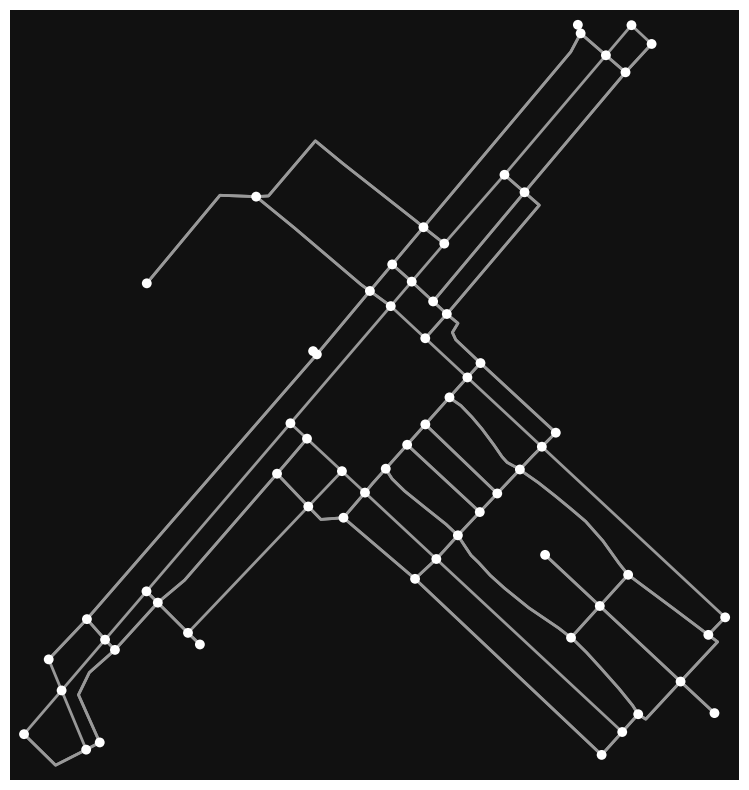

In [3]:
place_name = "Ho Chi Minh City"
# networkx graph of the named place
graph = ox.graph_from_address(place_name, dist=100)

fig, ax = ox.plot_graph(
    graph,
    figsize=(10, 10),
    edge_linewidth=2,  # mặc định là 1, bạn có thể thử 2, 3, 5...
    node_size=50     # ẩn các nút nếu bạn không cần
)
fig.savefig("hcm_graph.png", dpi=300)

In [4]:
center = ox.graph_to_gdfs(graph, nodes=False).unary_union.centroid
m = folium.Map(location=[center.y, center.x], zoom_start=15)

# Vẽ các cạnh (đường)
for u, v, data in graph.edges(data=True):
    if 'geometry' in data:
        coords = [(point[1], point[0]) for point in data['geometry'].coords]
    else:
        coords = [(graph.nodes[u]['y'], graph.nodes[u]['x']), (graph.nodes[v]['y'], graph.nodes[v]['x'])]

    folium.PolyLine(coords, color="blue", weight=2, opacity=0.6).add_to(m)

# Lưu bản đồ
m.save("graph_map.html")

/tmp/ipykernel_36/1362162987.py:1: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  center = ox.graph_to_gdfs(graph, nodes=False).unary_union.centroid


In [5]:
import json
import pandas as pd
import networkx as nx
import geojson
import pickle
from geojson import Feature, FeatureCollection, LineString
import geopandas as gpd

In [ ]:
G = None
with open("/kaggle/input/graph-networkx/graph-hochiminhcity.pkl", "rb") as f:
    G = pickle.load(f)
df = pd.read_csv("/kaggle/input/ahihiasd/betweenness (1).csv")
with open("/kaggle/input/ahihiasd/edge_removal_module.json") as f:
    edge_data = json.load(f)

In [ ]:
bet_map = {(row.u, row.v, row.key): row.betweenness for _, row in df.iterrows()}

edge_labels = {}
for item in edge_data:
    id_edge = item["id_edge"]
    delta = item["delta_cost"]
    start = tuple(item["start_edge"])
    for edge in item["delete_edges"]:
        edge_labels[tuple(edge)] = {
            "id_edge": id_edge,
            "delta_cost": delta,
            "type": "deleted"
        }



In [ ]:
rows = []
for (u, v, key), bet in bet_map.items():
    if not G.has_edge(u, v, key):
        continue
    try:
        geom = LineString([(G.nodes[u]['x'], G.nodes[u]['y']), (G.nodes[v]['x'], G.nodes[v]['y'])])
    except KeyError:
        continue

    label_info = edge_labels.get((u, v, key), {})
    rows.append({
        "u": u, "v": v, "key": key,
        "betweenness": bet,
        "id_edge": label_info.get("id_edge"),
        "delta_cost": label_info.get("delta_cost"),
        "type": label_info.get("type", "other"),
        "geometry": geom
    })


In [ ]:

gdf = gpd.GeoDataFrame(rows, crs="EPSG:4326")
gdf.to_file("edge_analysis.geojson", driver="GeoJSON")